# 02 · Baseline explicable: textura + modelos sencillos

**Objetivo:** fijar una referencia honesta antes de la CNN.

- **Métrica oficial:** EMD con peso logarítmico, es decir, el área entre la curva real y la predicha en escala log (0-500, menor es mejor).
- **Validación:** *leave-one-sample-out* (LOSO). Todas las fotos de una muestra salen juntas, porque con 24 muestras cualquier fuga entre fotos de la misma muestra inflaría el resultado.
- **Features:** recortes de 40×40 mm a 4,5 px/mm, con estadísticas de luminancia, color, gradientes, energía por escala y GLCM. Todo lo de textura se calcula sobre la luminancia normalizada por foto, para quitar el efecto de la cámara que vimos en el EDA.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from soilgrain.data import load_labels, load_photo, photo_index
from soilgrain.features import TARGET_PPM, photo_features
from soilgrain.gradation import soil_class
from soilgrain.metrics import SIEVES, emd, make_valid

warnings.filterwarnings("ignore", category=UserWarning)
FIG = ROOT / "reports" / "figures"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

CLASS_COLOR = {"finos": "#2a78d6", "arena": "#eb6834", "grava": "#1baf7a"}
CLASSES = list(CLASS_COLOR)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "figure.dpi": 110,
})

labels = load_labels()
Y = labels.values
sample_ids = labels.index.values
classes = pd.Series([soil_class(SIEVES, r) for r in Y], index=labels.index)

## 1. Referencias triviales (sin mirar las fotos)

In [2]:
def loso(predict_fn):
    """predict_fn(train_ids, test_id) -> curva predicha; devuelve EMD por muestra."""
    preds = np.vstack([predict_fn(np.delete(sample_ids, i), sid) for i, sid in enumerate(sample_ids)])
    preds = make_valid(preds)
    return pd.Series(emd(Y, preds), index=sample_ids), pd.DataFrame(preds, index=sample_ids, columns=labels.columns)

uniform = np.r_[np.linspace(100 / 11, 100 * 10 / 11, 10), 100]
results, oof = {}, {}
results["Uniforme (baseline de Kaggle)"], oof["uniforme"] = loso(lambda tr, te: uniform)
results["Curva media del train"], oof["media"] = loso(lambda tr, te: labels.loc[tr].mean().values)
results["Curva mediana del train"], oof["mediana"] = loso(lambda tr, te: labels.loc[tr].median().values)
pd.DataFrame({k: [v.mean(), v.std()] for k, v in results.items()}, index=["EMD medio", "desv."]).T.round(1)

,EMD medio,desv.
Uniforme (baseline de Kaggle),102.0,20.8
Curva media del train,89.9,25.8
Curva mediana del train,97.2,38.7


**La referencia que hay que batir es la curva media (EMD ≈ 90).** Con una métrica tipo L1 cabría esperar que ganase la mediana por tamiz, pero sale peor: las curvas son **bimodales** (finos frente a gravas), así que la mediana cae en uno de los modos y falla mucho en el otro, sobre todo en los finos. La media queda en medio y reparte el error.

## 2. Features por foto

In [3]:
cache = PROCESSED / f"features_ppm{TARGET_PPM}.csv"
photos = photo_index()
if cache.exists():
    feats = pd.read_csv(cache)
else:
    rows = []
    for p in photos.itertuples():
        rows.append({"file": p.path.name, **photo_features(load_photo(p.path, TARGET_PPM, p.ppm))})
    feats = pd.DataFrame(rows)
    feats.to_csv(cache, index=False)
feats = photos[["path", "split", "sample_id", "phone"]].assign(file=photos.path.map(lambda p: p.name)).merge(feats, on="file")
FEATURES = [c for c in feats.columns if c not in ("path", "file", "split", "sample_id", "phone", "n_patches")]
print(f"{len(feats)} fotos · {len(FEATURES)} features · {feats['n_patches'].sum()} recortes de 40×40 mm")
train = feats[feats["split"] == "train"].reset_index(drop=True)
test = feats[feats["split"] == "test"].reset_index(drop=True)

162 fotos · 60 features · 5617 recortes de 40×40 mm


## 3. Modelos

Entreno **por foto** (127 filas) y en validación promedio las predicciones de todas las fotos de la muestra que ha quedado fuera. Comparo dos modelos:

- **Ridge** multisalida: regresión lineal regularizada que predice los 10 tamices a la vez. El `alpha` se elige con una validación interna agrupada por muestra.
- **LightGBM**: un modelo por tamiz, con árboles muy pequeños, porque hay pocos datos.

En los dos casos la salida pasa por `make_valid`: se recorta a [0, 100], se fuerza la monotonía y el tamiz de 200 mm se fija en 100.

In [4]:
from lightgbm import LGBMRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TARGET_COLS = labels.columns[:-1]  # el tamiz de 200 mm siempre vale 100

def make_ridge():
    return GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                        {"ridge__alpha": np.logspace(-1, 4, 11)},
                        cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")

# Sin brillo ni color absolutos: lo que más desplaza la cámara según el EDA
CAMERA_SENSITIVE = ("lum_mean", "lum_std", "lum_p10", "lum_p90", "chroma_r", "chroma_g")
ROBUST = [f for f in FEATURES if not f.startswith(CAMERA_SENSITIVE)]

def make_ridge_robust():
    from sklearn.preprocessing import FunctionTransformer
    return GridSearchCV(make_pipeline(FunctionTransformer(lambda X: X[ROBUST]), StandardScaler(), Ridge()),
                        {"ridge__alpha": np.logspace(-1, 4, 11)},
                        cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")

def make_lgbm():
    return MultiOutputRegressor(LGBMRegressor(
        n_estimators=300, learning_rate=0.03, num_leaves=4, min_child_samples=10,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=5, verbose=-1))

def fit(model, df):
    y = labels.loc[df["sample_id"], TARGET_COLS].values
    if isinstance(model, GridSearchCV):
        model.fit(df[FEATURES], y, groups=df["sample_id"])
    else:
        model.fit(df[FEATURES], y)
    return model

def predict_samples(model, df):
    pred = pd.DataFrame(model.predict(df[FEATURES]), columns=TARGET_COLS)
    pred[200.0] = 100.0
    return pred.groupby(df["sample_id"].values).mean()

def loso_model(make_model, train_filter=None, eval_filter=None):
    preds = {}
    for sid in sample_ids:
        tr = train[train["sample_id"] != sid]
        te = train[train["sample_id"] == sid]
        if train_filter is not None:
            tr = tr[train_filter(tr)]
        if eval_filter is not None:
            te = te[eval_filter(te)]
        if len(te) == 0:
            continue
        preds[sid] = predict_samples(fit(make_model(), tr), te).loc[sid].values
    preds = pd.DataFrame(make_valid(np.vstack(list(preds.values()))), index=list(preds), columns=labels.columns)
    return pd.Series(emd(labels.loc[preds.index].values, preds.values), index=preds.index), preds

results["Ridge (textura)"], oof["ridge"] = loso_model(make_ridge)
results["LightGBM (textura)"], oof["lgbm"] = loso_model(make_lgbm)
results["Ridge (solo textura, sin color ni brillo)"], oof["ridge_robust"] = loso_model(make_ridge_robust)

In [5]:
table = pd.DataFrame({
    "EMD medio": {k: v.mean() for k, v in results.items()},
    "EMD mediana": {k: v.median() for k, v in results.items()},
    **{f"EMD {c}": {k: v[classes[v.index] == c].mean() for k, v in results.items()} for c in CLASSES},
}).round(1)
table

,EMD medio,EMD mediana,EMD finos,EMD arena,EMD grava
Uniforme (baseline de Kaggle),102.0,105.7,112.9,103.1,95.2
Curva media del train,89.9,90.1,111.6,79.7,81.5
Curva mediana del train,97.2,88.1,146.3,95.6,69.3
Ridge (textura),41.5,38.0,50.0,48.1,33.8
LightGBM (textura),42.4,32.1,52.6,51.8,32.6
"Ridge (solo textura, sin color ni brillo)",44.2,36.8,54.4,53.5,34.5


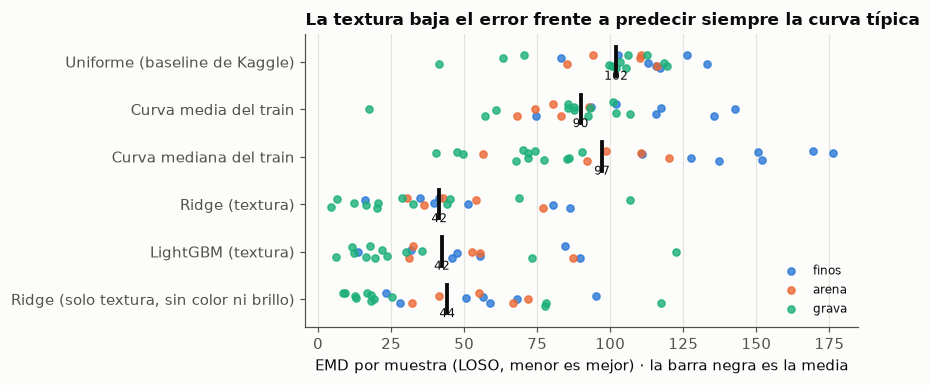

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(results)
for i, name in enumerate(names):
    s = results[name]
    for cls in CLASSES:
        v = s[classes[s.index] == cls]
        ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)),
                   s=22, color=CLASS_COLOR[cls], alpha=0.8, label=cls if i == 0 else None, zorder=3)
    ax.plot([s.mean()] * 2, [i - 0.3, i + 0.3], color=INK, lw=2.5, zorder=4)
    ax.text(s.mean(), i + 0.38, f"{s.mean():.0f}", ha="center", fontsize=8, color=INK)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("EMD por muestra (LOSO, menor es mejor) · la barra negra es la media")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("La textura baja el error frente a predecir siempre la curva típica", loc="left")
fig.tight_layout()
fig.savefig(FIG / "07_baseline_emd.png", dpi=150, bbox_inches="tight")

## 4. ¿Aguanta un cambio de cámara?

El test es todo iPhone y no tenemos ninguna foto de iPhone para validar. La mejor aproximación es **entrenar con una cámara y evaluar con la otra**: entreno solo con fotos del Motorola y evalúo en las fotos del Samsung de la muestra que queda fuera, y al revés. Si el error se dispara frente al LOSO normal, el modelo depende de la cámara.

In [7]:
moto = lambda d: d["phone"].str.startswith("Motorola")
sams = lambda d: d["phone"] == "Samsung A52"
setups = {
    "Misma cámara (Samsung → Samsung)": (sams, sams),
    "Motorola → Samsung": (moto, sams),
    "Misma cámara (Motorola → Motorola)": (moto, moto),
    "Samsung → Motorola": (sams, moto),
}
cross = pd.DataFrame({
    model_name: {setup: loso_model(maker, tr, ev)[0].mean() for setup, (tr, ev) in setups.items()}
    for model_name, maker in [("Ridge (todas)", make_ridge), ("Ridge (sin color ni brillo)", make_ridge_robust)]
})
cross.round(1)

,Ridge (todas),Ridge (sin color ni brillo)
Misma cámara (Samsung → Samsung),48.2,50.0
Motorola → Samsung,83.3,70.2
Misma cámara (Motorola → Motorola),51.9,47.6
Samsung → Motorola,71.9,53.2


**Lectura:** al cambiar de cámara, el error con todas las features sube mucho respecto a usar la misma cámara. Quitar el color y el brillo absolutos hace el modelo **más estable entre cámaras**, aunque en el LOSO normal pierda algo de precisión. Como el test es todo iPhone, **elijo para el envío el modelo robusto**: un compromiso deliberado entre la precisión en validación y la generalización.

## 5. ¿Qué mira el modelo?

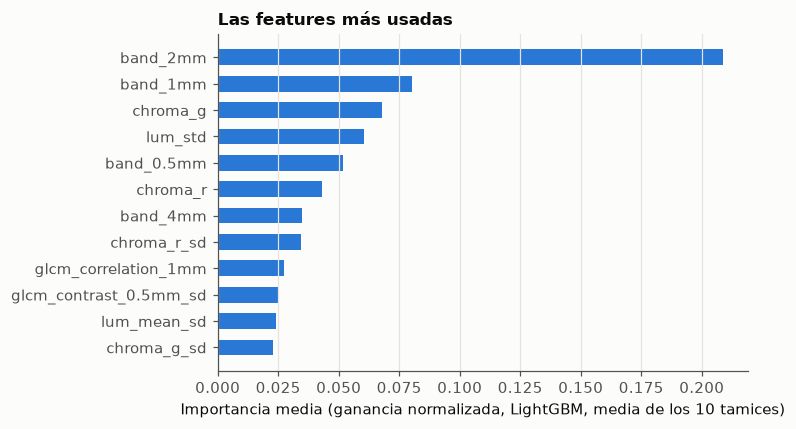

In [8]:
lgbm_full = fit(make_lgbm(), train)
gain = pd.DataFrame({col: est.booster_.feature_importance("gain") for col, est in zip(TARGET_COLS, lgbm_full.estimators_)},
                    index=FEATURES)
gain = gain / gain.sum()
top = gain.mean(axis=1).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(range(len(top)), top.values, color="#2a78d6", height=0.6)
ax.set_yticks(range(len(top)), top.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Importancia media (ganancia normalizada, LightGBM, media de los 10 tamices)")
ax.set_title("Las features más usadas", loc="left")
fig.tight_layout()
fig.savefig(FIG / "08_importancia_features.png", dpi=150, bbox_inches="tight")

## 6. Curvas reales frente a predichas

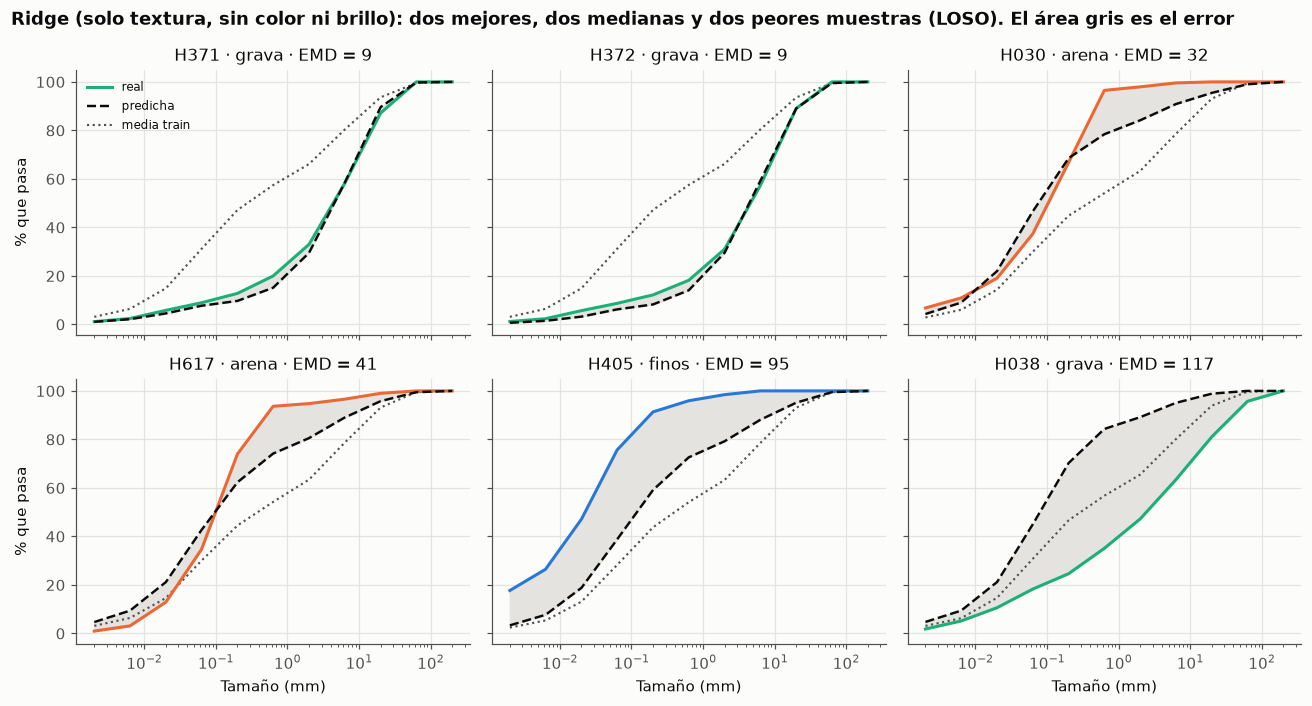

In [9]:
best_name, best_key, best_maker = "Ridge (solo textura, sin color ni brillo)", "ridge_robust", make_ridge_robust
best_res = results[best_name].sort_values()
show = list(best_res.index[:2]) + list(best_res.index[len(best_res) // 2 - 1:len(best_res) // 2 + 1]) + list(best_res.index[-2:])
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, sid in zip(axes.flat, show):
    cls = classes[sid]
    ax.fill_between(SIEVES, labels.loc[sid], oof[best_key].loc[sid], step=None, color=GRID, zorder=1)
    ax.plot(SIEVES, labels.loc[sid], color=CLASS_COLOR[cls], label="real", zorder=3)
    ax.plot(SIEVES, oof[best_key].loc[sid], color=INK, ls="--", lw=1.6, label="predicha", zorder=3)
    ax.plot(SIEVES, oof["media"].loc[sid], color=INK_2, ls=":", lw=1.4, label="media train", zorder=2)
    ax.set_xscale("log")
    ax.set_title(f"{sid} · {cls} · EMD = {best_res[sid]:.0f}", fontweight="normal")
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("% que pasa")
for ax in axes[-1]:
    ax.set_xlabel("Tamaño (mm)")
fig.suptitle(f"{best_name}: dos mejores, dos medianas y dos peores muestras (LOSO). El área gris es el error",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "09_curvas_predichas.png", dpi=150, bbox_inches="tight")

## 7. Envío

In [10]:
final = fit(best_maker(), train)
sub = predict_samples(final, test)
sub = pd.DataFrame(make_valid(sub.values), index=sub.index, columns=labels.columns)
template = pd.read_csv(ROOT / "data" / "raw" / "sample_submission.csv")
sub = sub.loc[template["sample_id"]]
sub.columns = template.columns[1:]
SUBMISSIONS = ROOT / "submissions"
SUBMISSIONS.mkdir(exist_ok=True)
out = SUBMISSIONS / f"baseline_{best_key}.csv"
sub.round(4).to_csv(out, index_label="sample_id")
assert (np.diff(sub.values, axis=1) >= 0).all() and (sub.values[:, -1] == 100).all()
print("Guardado en", out.relative_to(ROOT))
sub.round(1)

Guardado en submissions/baseline_ridge_robust.csv


,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
HPC_Airbus BS6-3,2.7,6.5,17.3,43.1,68.7,78.6,83.9,89.8,95.9,99.4,100.0
HPC_Audorfring,3.1,6.4,15.3,33.3,52.8,64.2,72.3,84.3,94.4,99.4,100.0
HPC_Muenster_BS6_9_0-10m,0.0,0.0,0.0,2.0,11.8,14.1,26.7,53.3,88.3,99.0,100.0
HPC_Airbus BS10-4bis7,2.5,6.2,16.9,43.3,70.4,80.6,85.9,91.4,96.7,99.5,100.0
HPC_Airbus BS12-5bis8,2.4,5.9,16.2,40.7,65.2,74.8,80.9,88.0,95.5,99.3,100.0
HPC_Kleinkummerfeld 2-2,3.6,7.7,18.7,40.5,66.4,81.7,86.9,93.4,97.6,99.6,100.0
HPC_Kleinkummerfeld 2-3,3.8,8.1,20.1,43.8,68.7,81.6,87.5,93.9,97.5,99.7,100.0
HPC_Kleinkummerfeld 9-4,2.3,5.7,15.3,38.8,63.6,74.5,81.2,89.0,95.8,99.5,100.0
HPC_Kleinkummerfeld 18-3,3.0,6.8,17.6,41.0,65.1,76.3,82.3,89.5,96.1,99.4,100.0
HPC_Testfeld Lidl WHV,1.2,2.6,6.7,15.2,22.7,28.1,39.7,62.3,88.6,98.6,100.0


## Conclusiones

Las cifras concretas están en las tablas de arriba. En resumen:

1. **La textura aporta señal real**: los modelos con features de imagen reducen aproximadamente a la mitad el EMD de la curva media del train.
2. **El error no se reparte igual entre clases**; la tabla por clase muestra dónde falla. Era de esperar por el EDA: terrones de finos que parecen grava y gravas enterradas en matriz.
3. **El mayor riesgo es la cámara, no el modelo.** Entrenar con un móvil y evaluar con otro dispara el error. Por eso el envío usa solo features de textura normalizada, aunque en el LOSO no sea el mejor. Es una aproximación, porque los iPhone no están en el train.
4. **Siguiente paso:** CNN preentrenada sobre los mismos recortes a escala común, con salida monótona (softmax de incrementos y suma acumulada) y entrenada directamente con la EMD como pérdida.